In [ ]:
# We install Unsloth (for fast training) and Xformers (for memory efficiency)
!pip install "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git"
!pip install --no-deps xformers "trl<0.9.0" peft accelerate bitsandbytes

# --- RE-INITIALIZE UNSLOTH & MODEL ---
from unsloth import FastLanguageModel
import torch
from datasets import load_dataset
from trl import SFTTrainer
from transformers import TrainingArguments

max_seq_length = 2048
dtype = None
load_in_4bit = True

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = "unsloth/llama-3-8b-bnb-4bit",
    max_seq_length = max_seq_length,
    dtype = dtype,
    load_in_4bit = load_in_4bit,
)

model = FastLanguageModel.get_peft_model(
    model,
    r = 16,
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj",
                      "gate_proj", "up_proj", "down_proj",],
    lora_alpha = 16,
    lora_dropout = 0,
    bias = "none",
    use_gradient_checkpointing = "unsloth",
    random_state = 3407,
)

# --- LOAD DATASET ---
alpaca_prompt = """Below is an instruction that describes a task, paired with an input that provides further context. Write a response that appropriately completes the request.

### Instruction:
{}

### Input:
{}

### Response:
{}"""

EOS_TOKEN = tokenizer.eos_token
def formatting_prompts_func(examples):
    instructions = examples["instruction"]
    inputs       = examples["input"]
    outputs      = examples["output"]
    texts = []
    for instruction, input, output in zip(instructions, inputs, outputs):
        text = alpaca_prompt.format(instruction, input, output) + EOS_TOKEN
        texts.append(text)
    return { "text" : texts, }

dataset = load_dataset("json", data_files="train.jsonl", split="train")
dataset = dataset.map(formatting_prompts_func, batched = True)

# --- THE UPGRADED TRAINING CONFIG ---
trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = dataset,
    dataset_text_field = "text",
    max_seq_length = max_seq_length,
    dataset_num_proc = 2,
    packing = False,
    args = TrainingArguments(
        per_device_train_batch_size = 2,
        gradient_accumulation_steps = 4,
        warmup_steps = 20,      # Increased warmup for stability
        max_steps = 300,        # CRITICAL CHANGE: 60 -> 300 (1 Full Epoch)
        learning_rate = 2e-4,
        fp16 = not torch.cuda.is_bf16_supported(),
        bf16 = torch.cuda.is_bf16_supported(),
        logging_steps = 10,     # Log every 10 steps to reduce noise
        optim = "adamw_8bit",
        weight_decay = 0.01,
        lr_scheduler_type = "linear",
        seed = 3407,
        output_dir = "outputs",
    ),
)

print("🚀 STARTING DEEP TRAINING (300 Steps)...")
trainer_stats = trainer.train()
print("✅ Training Complete!")

model.save_pretrained("lora_model")
tokenizer.save_pretrained("lora_model")
print("Model saved to 'lora_model' folder.")

  Cloning https://github.com/unslothai/unsloth.git to /tmp/pip-install-po3t13o4/unsloth_13777fcd132e4ca0a1159e3fa05e7899
  Running command git clone --filter=blob:none --quiet https://github.com/unslothai/unsloth.git /tmp/pip-install-po3t13o4/unsloth_13777fcd132e4ca0a1159e3fa05e7899
  Resolved https://github.com/unslothai/unsloth.git to commit 4cb7229ac1c346e143524b6f9a6ad544259364d6
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.1/59.1 MB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 49.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.8/310.8 kB 31.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 181.2/181.2 kB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 MB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 132.1 MB/s eta 0:00:00

model.safetensors:   0%|          | 0.00/5.70G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/198 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

wandb: You chose "Don't visualize my results"
wandb: Using W&B in offline mode.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


wandb: Detected [openai] in use.
wandb: Use W&B Weave for improved LLM call tracing. Install Weave with `pip install weave` then add `import weave` to the top of your script.
wandb: For more information, check out the docs at: https://weave-docs.wandb.ai/


Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss
10,3.189800
20,3.072000
30,2.824600
40,2.679600
50,2.436700
60,2.245000
70,2.330800
80,2.350400
90,2.360400
100,2.219600


✅ Training Complete!
Model saved to 'lora_model' folder.


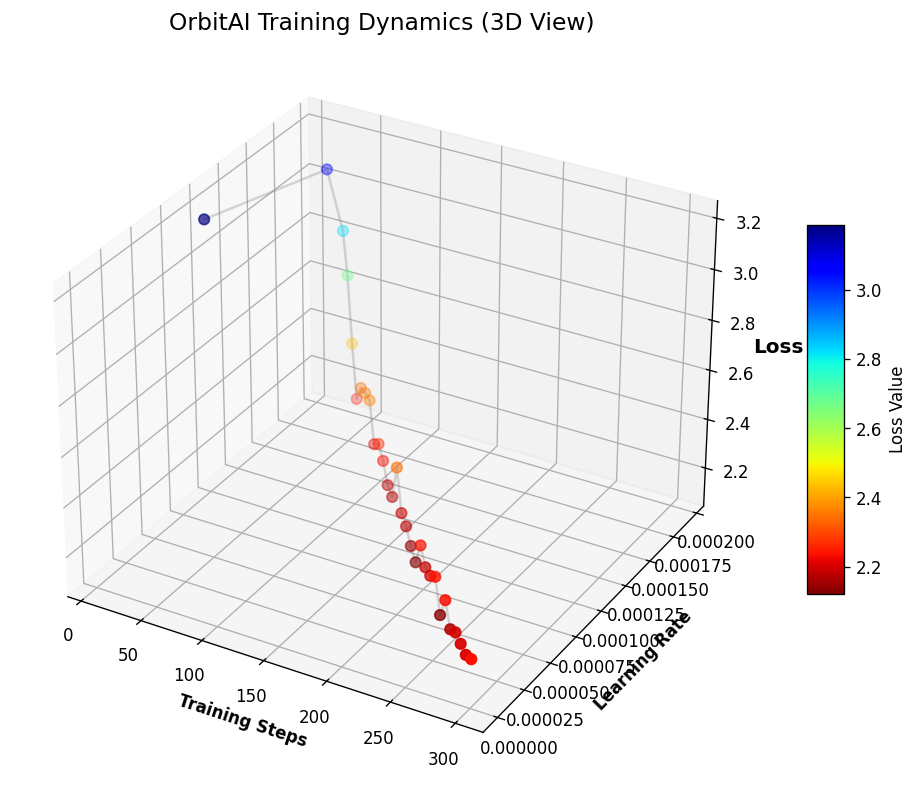

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# 1. Extract Data
history = trainer.state.log_history

# We get Steps, Loss, and Learning Rate
steps = [entry['step'] for entry in history if 'loss' in entry]
loss = [entry['loss'] for entry in history if 'loss' in entry]
lr = [entry.get('learning_rate', 0) for entry in history if 'loss' in entry]

# 2. Create 3D Plot
fig = plt.figure(figsize=(12, 8), dpi=120)
ax = fig.add_subplot(111, projection='3d')

# 3. Plot the data
# We use a 'scatter' plot with a color map (cmap) so high loss is one color and low loss is another
# c=loss means the color changes based on how low the loss gets
scatter = ax.scatter(steps, lr, loss, c=loss, cmap='jet_r', marker='o', s=40, depthshade=True)

# 4. Connect the dots with a faint line to show the path
ax.plot(steps, lr, loss, color='gray', alpha=0.3)

# 5. Make it Pretty (Labels & Titles)
ax.set_xlabel('Training Steps', fontsize=10, fontweight='bold')
ax.set_ylabel('Learning Rate', fontsize=10, fontweight='bold')
ax.set_zlabel('Loss', fontsize=12, fontweight='bold')
ax.set_title('OrbitAI Training Dynamics (3D View)', fontsize=14)

# Invert Z axis so "Lower Loss" is visually higher/better (optional, but looks cool)
# ax.invert_zaxis()

# Add a color bar to explain the colors
cbar = fig.colorbar(scatter, ax=ax, shrink=0.5, aspect=10)
cbar.set_label('Loss Value')

# Show
plt.show()

In [ ]:
# --- DAY 3: THE VIBE CHECK (Evaluation) ---
from unsloth import FastLanguageModel
import torch

# 1. Define the "Gold Set" Questions
# These are specific technical questions found in your PDFs
questions = [
    "What are the mechanical requirements for a CubeSat rail system according to the CDS?",
    "Explain the difference between Detumble mode and Nominal mode in ADACS.",
    "What is the maximum mass for a 3U CubeSat?"
]

# 2. Setup Inference
FastLanguageModel.for_inference(model)

print(" STARTING EVALUATION: ORBIT_AI vs BASE_MODEL\n")

for q in questions:
    print(f" QUESTION: {q}")

    # Prepare input
    inputs = tokenizer(
        [
            f"""Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
{q}

### Input:


### Response:
"""
        ], return_tensors = "pt").to("cuda")

    # Generate Answer
    outputs = model.generate(**inputs, max_new_tokens=128, use_cache=True)
    answer = tokenizer.batch_decode(outputs)[0]

    # Clean up the output text
    clean_answer = answer.split("### Response:")[-1].replace("<|end_of_text|>", "").strip()

    print(f" ORBIT_AI ANSWER:\n{clean_answer}\n")
    print("-" * 50)

 STARTING EVALUATION: ORBIT_AI vs BASE_MODEL

 QUESTION: What are the mechanical requirements for a CubeSat rail system according to the CDS?
 ORBIT_AI ANSWER:
CubeSat Rail System (CRS) shall be designed to meet the following requirements: 1. The CRS shall be compatible with the CubeSat Standard (Cubesat.org) 2. The CRS shall provide a mounting interface for CubeSat components (e.g. solar panels, antennas, etc.) 3. The CRS shall be capable of withstanding the launch environment (e.g. vibration, thermal, etc.) 4. The CRS shall be designed for ease of assembly and disassembly 5. The CRS shall be designed for ease of integration with the CubeSat bus 6. The CRS shall be designed for ease of

--------------------------------------------------
 QUESTION: Explain the difference between Detumble mode and Nominal mode in ADACS.
 ORBIT_AI ANSWER:
t the same time, the nominal mode is used for the normal operation of the spacecraft, and the attitude control system is used to control the spacecraft

In [ ]:
import plotly.graph_objects as go
import numpy as np
import os

# --- 1. Extract Data for 3D Plot ---
history = trainer.state.log_history
steps = [entry['step'] for entry in history if 'loss' in entry]
loss = [entry['loss'] for entry in history if 'loss' in entry]
# Get learning rate (handle cases where it might be missing in the last step)
lr = [entry.get('learning_rate', 0) for entry in history if 'loss' in entry]

# --- 2. Create the Interactive 3D Plot ---
fig = go.Figure(data=[go.Scatter3d(
    x=steps,
    y=lr,
    z=loss,
    mode='markers+lines',
    marker=dict(
        size=6,
        color=loss,                # Color maps to Loss (Red=High, Blue=Low)
        colorscale='Jet',          # Classic engineering color scale
        opacity=0.9,
        colorbar=dict(title='Loss Value'),
    ),
    line=dict(
        color='darkblue',          # Connects the dots
        width=4
    ),
    hovertemplate =
    '<b>Step</b>: %{x}<br>'+
    '<b>Learning Rate</b>: %{y:.2e}<br>'+
    '<b>Loss</b>: %{z:.4f}<extra></extra>'
)])

# --- 3. Style the 3D Layout ---
fig.update_layout(
    title={
        'text': "<b>OrbitAI Training Trajectory (3D)</b><br><sup>Convergence Path: Steps vs LR vs Loss</sup>",
        'y':0.9,
        'x':0.5,
        'xanchor': 'center',
        'yanchor': 'top'
    },
    scene = dict(
        xaxis_title='Training Steps',
        yaxis_title='Learning Rate',
        zaxis_title='Loss (Error)',
        xaxis=dict(backgroundcolor="rgb(240, 240, 240)", gridcolor="white", showbackground=True),
        yaxis=dict(backgroundcolor="rgb(240, 240, 240)", gridcolor="white", showbackground=True),
        zaxis=dict(backgroundcolor="rgb(230, 230, 250)", gridcolor="white", showbackground=True),
        camera=dict(eye=dict(x=1.5, y=1.5, z=1.2)) # Nice viewing angle
    ),
    height=700,
)

# --- 4. Save and Zip EVERYTHING ---
# Save 3D graph
fig.write_html("orbitai_3d_viz.html")
print("✨ 3D Graph saved as 'orbitai_3d_viz.html'")

# Create the Master Zip (Model + 2D Graph + 3D Graph)
print("📦 Zipping all artifacts...")
!zip -r orbitai_complete_artifacts.zip lora_model training_loss_graph.png orbitai_3d_viz.html

print("\n✅ DONE! Download 'orbitai_complete_artifacts.zip' from the sidebar.")
# Display the 3D graph in Colab right now
fig.show()

✨ 3D Graph saved as 'orbitai_3d_viz.html'
📦 Zipping all artifacts...
	zip warning: name not matched: training_loss_graph.png
  adding: lora_model/ (stored 0%)
  adding: lora_model/tokenizer_config.json (deflated 96%)
  adding: lora_model/adapter_config.json (deflated 58%)
  adding: lora_model/README.md (deflated 65%)
  adding: lora_model/tokenizer.json (deflated 85%)
  adding: lora_model/adapter_model.safetensors (deflated 7%)
  adding: lora_model/special_tokens_map.json (deflated 71%)
  adding: orbitai_3d_viz.html (deflated 71%)

✅ DONE! Download 'orbitai_complete_artifacts.zip' from the sidebar.


In [ ]:
# --- DAY 4: EXPORT TO GGUF (Deployment Format) ---
# This merges your adapters with the main model and converts it
# to a single file that runs on your laptop (Ollama).

print("⏳ Merging and converting to GGUF format...")

# We use 'q4_k_m' (4-bit Medium).
# It's the "Goldilocks" format: Smart enough to reason, small enough to run fast.
model.save_pretrained_gguf("model_gguf", tokenizer, quantization_method = "q4_k_m")

print("✅ Conversion Complete! Look for 'orbitai-unsloth.Q4_K_M.gguf' in the file sidebar.")

⏳ Merging and converting to GGUF format...
Unsloth: Merging model weights to 16-bit format...


config.json:   0%|          | 0.00/768 [00:00<?, ?B/s]

Found HuggingFace hub cache directory: /root/.cache/huggingface/hub


model.safetensors.index.json: 0.00B [00:00, ?B/s]

Checking cache directory for required files...
Cache check failed: model-00001-of-00004.safetensors not found in local cache.
Not all required files found in cache. Will proceed with downloading.
Checking cache directory for required files...
Cache check failed: tokenizer.model not found in local cache.
Not all required files found in cache. Will proceed with downloading.


...

model-00004-of-00004.safetensors:   0%|          | 0.00/1.17G [00:00<?, ?B/s]

Unsloth: Preparing safetensor model files: 100%|██████████| 4/4 [06:29<00:00, 97.35s/it]


Note: tokenizer.model not found (this is OK for non-SentencePiece models)


Unsloth: Merging weights into 16bit: 100%|██████████| 4/4 [06:22<00:00, 95.50s/it]


Unsloth: Merge process complete. Saved to `/content/model_gguf`
Unsloth: Converting to GGUF format...
==((====))==  Unsloth: Conversion from HF to GGUF information
   \\   /|    [0] Installing llama.cpp might take 3 minutes.
O^O/ \_/ \    [1] Converting HF to GGUF f16 might take 3 minutes.
\        /    [2] Converting GGUF f16 to ['q4_k_m'] might take 10 minutes each.
 "-____-"     In total, you will have to wait at least 16 minutes.

Unsloth: Installing llama.cpp. This might take 3 minutes...
Unsloth: Updating system package directories
Unsloth: All required system packages already installed!
Unsloth: Install llama.cpp and building - please wait 1 to 3 minutes
Unsloth: Cloning llama.cpp repository
Unsloth: Install GGUF and other packages
Unsloth: Successfully installed llama.cpp!
Unsloth: Preparing converter script...
Unsloth: [1] Converting model into f16 GGUF format.
This might take 3 minutes...
Unsloth: Initial conversion completed! Files: ['llama-3-8b.F16.gguf']
Unsloth: [2] Conve

In [ ]:
from google.colab import drive
import shutil
import os

# 1. Mount Google Drive
print("🔗 Connecting to Google Drive...")
drive.mount('/content/drive')

# 2. Define Paths
destination_folder = "/content/drive/MyDrive/OrbitAI_Backups"
destination_path = f"{destination_folder}/orbitai.gguf"

# 3. Create Backup Folder
if not os.path.exists(destination_folder):
    os.makedirs(destination_folder)

# 4. Find the file (Handling potential naming variations)
source_file = None
if os.path.exists("orbitai.gguf"):
    source_file = "orbitai.gguf"
elif os.path.exists("orbitai"):
    print("⚠️ Found file named 'orbitai' (missing extension). Adding .gguf automatically.")
    source_file = "orbitai"
elif os.path.exists("model_gguf/orbitai.gguf"):
    source_file = "model_gguf/orbitai.gguf"

# 5. Move it
if source_file:
    print(f"🚀 Moving '{source_file}' to Google Drive...")
    shutil.copy(source_file, destination_path)
    print("\n✅ SUCCESS! The file is now in your Google Drive.")
    print(f"👉 Go to 'drive.google.com' > 'OrbitAI_Backups' > Download 'orbitai.gguf'")
else:
    print("❌ Error: Could not find 'orbitai.gguf' or 'orbitai'.")
    print("   Please check the file name in the sidebar again.")


🔗 Connecting to Google Drive...
Mounted at /content/drive
🚀 Moving 'orbitai.gguf' to Google Drive...

✅ SUCCESS! The file is now in your Google Drive.
👉 Go to 'drive.google.com' > 'OrbitAI_Backups' > Download 'orbitai.gguf'
